# Comparison of 2 calibrations 

Comparision of two method of calibration:

- Brucker software 
- Automatic inhouse calibraiton base on mass difference map error

In [96]:
import spectre_analysis as sp_ana
import calibration as cal
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import os
import gc

from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from pathlib import Path
from scipy.stats import gaussian_kde
from typing import Dict, Union, Optional, Tuple, List

#import datashader as ds
#from datashader import transfer_functions as tf
#import colorcet as cc

## Data extraction

In [2]:
workers = 1

In [5]:
path_spectrum_all = Path.cwd().parent / "data" / "calibration" / "spectrum" / "all"
path_spectrum_selection = Path.cwd().parent / "data" / "calibration" / "spectrum" / "selection"

In [6]:
def select_sepctrum(path_to_analyse):
    path_cal = Path.cwd().parent / "data" / "Standard_Gums_Calibrated_files"

    list_std = os.listdir(path_to_analyse)
    list_cal = os.listdir(path_cal)
    list_cal = [i.replace("_Calibrated", "") for i in list_cal]

    # take the commun spectra of the both folders
    spectra = sorted(list(set(list_std) & set(list_cal)))
    for i in spectra:
        print(i)
    return spectra

In [11]:
path_to_analyse = Path.cwd().parent / "data" / "standards"
spectra = select_sepctrum(path_to_analyse)

18052022-arabinogalactane-0.01mg_0_0_L13_000001.csv
18052022-arabinogalactane-0.01mg_0_0_L13_000002.csv
18052022-arabinogalactane-0.01mg_0_G15_000001.csv
18052022-arabinogalactane-0.01mg_0_G16_000001.csv
18052022-arabinogalactane-0.1mg_0_G13_000001.csv
18052022-arabinogalactane-0.1mg_0_H13_000001.csv
18052022-arabinogalactane-1mg_0_G11_000001.csv
18052022-arabinogalactane-1mg_0_G12_000001.csv
18052022-galactomannane-1mg_0_0_H6_000001.csv
18052022-galactomannane-1mg_0_0_H6_000002.csv
18052022-galactomannane-1mg_0_H6_000003.csv
18052022-galactomannane-1mg_OK_0_G6_000001.csv
18052022-galactomannane-1mg_OK_0_G6_000002.csv


## Calibration All Monomers

*NOTE:*  
With all monomers it is impossible to run every spectrum in the same time but for some of them it is possible to run the callibration one by one

In [16]:
# 1) All monomers

monomers_list = ["dHex", "Hex", "HexA", "HexN", "HexNac", "Pent", "Neu", "NeuAc", "NeuGc"]
library = Path.cwd().parent / "data" / "oligo_combinations_clean.csv"
oligo_ref_all = sp_ana.adjust_library(library, monomers_list)
# Transform the mass in ppm and int to optimize the algorithm
for adduct in ['labeled_mass_H+', 'labeled_mass_Na+', 'labeled_mass_K+']:
    oligo_ref_all = sp_ana.normalize_mz_column(
    lf = oligo_ref_all,
    mz_col=adduct,
    new_col=f"{adduct}_int"
)

def save_spectrum(spectrum, path, spectrum_name ):
    file_name = Path(path) / spectrum_name
    print(file_name)
    spectrum.collect().write_csv(file_name, separator=',')


    
def process_spectrum_pipeline(
    spectrum_name: str,
    workers: int,
    oligo_ref_all: pl.LazyFrame,
    data_dir: Path = Path.cwd().parent / "data" / "standards",
    output_dir: Path = Path.cwd() / "output"
) -> None:
    """
    Execute the complete MALDI spectrum processing pipeline as originally implemented.
    Returns (spectrum_std, peaks, calibrated) as LazyFrames without modifying the original logic.

    Args:
        spectrum_name: Name of the spectrum file to process (e.g., "sample1.csv")
        workers: Number of parallel workers for peak detection
        oligo_ref_all: Reference oligomer data (LazyFrame)
        data_dir: Directory containing spectrum files (default: ../data/standards)
        output_dir: Directory for calibration output (default: ./output)

    Returns:
        Tuple of (standardized spectrum, detected peaks, calibrated spectrum) as LazyFrames
    """
    # --- Original code preserved exactly ---
    print(f"[INFO] Starting analysis for {spectrum_name}")
    spectrum_file = data_dir / spectrum_name
    spectrum_std: pl.LazyFrame = (
        sp_ana.read_spectrum(spectrum_file)
        .pipe(lambda df: df.lazy())  # Kept as in your original
    )

    # Peak detection pipeline
    print("[INFO] Extracting peaks with adaptive parameters")
    peaks: pl.LazyFrame = (
        sp_ana.extract_and_detect_peaks(
            spectrum_data=spectrum_std,
            window=500,
            dist_min=0,
            prominence=3e5,
            n_workers=workers
        )
    )

    # Mass normalization
    print("[INFO] Normalizing m/z values")
    peaks = sp_ana.normalize_mz_column(
        lf=peaks,
        mz_col="m/z",
        new_col="mz_int"
    )

    # Calibration
    print("[INFO] Calibration all monomers")
    calibrated_lf = cal.process_calibration(
        spectrum_name,
        spectrum_std,
        peaks,
        oligo_ref_all,
        output_dir,
        "all_mono"
    )

    # =========================
    # 5️⃣ Forcer exécution + libération mémoire
    # =========================
    _ = calibrated_lf.collect(streaming=True)

    # =========================
    # 6️⃣ Nettoyage explicite
    # =========================
    del spectrum_std
    del peaks
    del calibrated_lf


In [ ]:
spectrum_name = "18052022-galactomannane-1mg_OK_0_G6_000002.csv"

process_spectrum_pipeline(
    spectrum_name=spectrum_name,
    workers=1,
    oligo_ref_all=oligo_ref_all,
    output_dir=path_spectrum_all,
)
gc.collect()

## Calibration Selected Monomers

In [ ]:

# 2) Selection of mmonomers

monomers_list = ["Hex", "Pent"]
library = Path.cwd().parent / "data" / "oligo_combinations.csv"
oligo_ref_selection = sp_ana.adjust_library(library, monomers_list)
# Transform the mass in ppm and int to optimize the algorithm
for adduct in ['labeled_mass_H+', 'labeled_mass_Na+', 'labeled_mass_K+']:
    oligo_ref_selection = sp_ana.normalize_mz_column(
    lf = oligo_ref_selection,
    mz_col=adduct,
    new_col=f"{adduct}_int"
)

Execute the **test_calibration.py** script

## Analysis

In [18]:
def extract_and_concact_peaks(spectra, path_spectrum_calibrated, path_peaks, mz_col_to_select, workers):
    all_peaks = []

    for spectrum_name in spectra:

        # Spectrum extraction with progress logging
        print(f"[INFO] Starting analysis for {spectrum_name}")
        spectrum_file = Path.cwd().parent / "data" / "standards" / spectrum_name
        spectrum_origin: pl.LazyFrame = (
            sp_ana.read_spectrum(spectrum_file)
            .pipe(lambda df: df.lazy())  # Ensure LazyFrame if not already
            )
        
        spectrum_file = Path.cwd().parent / "data" / "Standard_Gums_Calibrated_files" / (
        spectrum_name.replace(".csv", "") + "_Calibrated.csv")
        spectrum_bruker = sp_ana.read_spectrum(spectrum_file)

        spectrum_file = path_spectrum_calibrated / spectrum_name
        spectrum_calibrate: pl.LazyFrame = (
            sp_ana.read_spectrum(spectrum_file, mz_col_to_select)
            .pipe(lambda df: df.lazy())  # Ensure LazyFrame if not already
            )

        # Peak detection pipeline
        print("[INFO] Extracting peaks of origninal spectrum")
        peaks = (
            spectrum_origin
            .pipe(lambda df: sp_ana.extract_and_detect_peaks(
                spectrum_data=df,
                window=500,
                dist_min=0,
                prominence=3e5,
                n_workers=workers
            ))
            .pipe(lambda df: sp_ana.normalize_mz_column(
                lf=df,
                mz_col="m/z",
                new_col="mz_int"
            ))
        )

        print("[INFO] Extracting peaks of calibrated spectrum")
        peaks_calibrated = sp_ana.extract_and_detect_peaks(
            spectrum_data=spectrum_calibrate,
            window=500,
            dist_min=0,
            prominence=3e5,
            n_workers=1,
            mz_col=mz_col_to_select,
            intensity_col="Intensity"
        ).collect().lazy()

        print("[INFO] Extracting peaks of bruker spectrum")
        peaks_bruker = sp_ana.extract_and_detect_peaks(
            spectrum_data=spectrum_bruker,
            window=500,
            dist_min=0,
            prominence=3e5,
            n_workers=1,
        ).rename({"m/z":"bruker"}).collect().lazy()

        # Join
        print('[INFO] Join the spectrum')
        peaks_idx = peaks.with_row_index("idx")
        peaks_calibrated_idx = peaks_calibrated.with_row_index("idx")
        peaks_bruker_idx = peaks_bruker.with_row_index("idx")

        global_data = (
            peaks_idx
            .join(peaks_calibrated_idx, on="idx", how="inner", suffix="_sel")
            .join(peaks_bruker_idx, on="idx", how="inner", suffix="_bruker")
            .drop(["Intensity_sel", "Intensity_bruker"])
            .with_columns(pl.lit(spectrum_name).alias("Spectrum_Name"))
        )

        save_spectrum(global_data, path_peaks, spectrum_name)
        all_peaks.append(global_data)
        # Free memory
        del peaks, peaks_bruker, peaks_calibrated, 
        del peaks_idx, peaks_bruker_idx, peaks_calibrated_idx, 
        del spectrum_origin, spectrum_calibrate, spectrum_bruker
        del global_data
        gc.collect()


    print("[INFO] Final concatenation")
    return pl.concat(all_peaks,  rechunk=True)



In [30]:
def calculate_metrics(
    df: pl.LazyFrame,
    ref_col: str = "ref",
    predict_col: str = "predict"
) -> Tuple[float, float, float]:
    """
    Compute RMSE, MAE, and R² between reference and predicted values in a Polars LazyFrame.
    Optimized for large datasets (e.g., MALDI-TOF spectra with ~1M rows).

    Args:
        df: LazyFrame containing reference and predicted columns.
        ref_col: Name of the reference column (true values).
        predict_col: Name of the predicted column.

    Returns:
        dict[str, float]: Dictionary with keys {"rmse", "mae", "r2"}.
    """
    # Calculate residuals and metrics in a single pass
    metrics = (
        df
        .select(
            # RMSE: sqrt(mean((ref - predict)²))
            ((pl.col(ref_col) - pl.col(predict_col)) ** 2).mean().sqrt().alias("rmse"),
            # MAE: mean(|ref - predict|)
            (pl.col(ref_col) - pl.col(predict_col)).abs().mean().alias("mae"),
            # R²: 1 - (SS_res / SS_tot)
            ((pl.col(ref_col) - pl.col(predict_col)) ** 2).sum().alias("ss_res"),
            ((pl.col(ref_col) - pl.col(ref_col).mean()) ** 2).sum().alias("ss_tot"),
        )
        .collect()
        .row(0)
    )

    rmse, mae, ss_res, ss_tot = metrics

    # Extract R² components
    r2 = 1.0 - (ss_res / ss_tot) if ss_tot != 0 else float('nan')

    return rmse, mae, r2


In [ ]:
def plot_performance(
    df: pl.LazyFrame,
    ref_col: str = "ref",
    predict_col: str = "predict",
    figsize: Tuple[float, float] = (12, 10),
    alpha: float = 0.5,
    color: str = "#4E79A7",
    xlim: Optional[Tuple[float, float]] = None,
) -> plt.Figure:
    """
    Génère deux plots pour évaluer les performances de prédiction :
    1. Scatter plot : ref vs predicted (avec ligne y=x)
    2. Erreurs standardisées : (ref - predicted)/ref * 1e6 (ppm) vs predicted

    Args:
        df: LazyFrame contenant les colonnes de référence et prédites.
        ref_col: Nom de la colonne de référence (valeurs réelles).
        predict_col: Nom de la colonne prédite.
        figsize: Taille de la figure (largeur, hauteur).
        alpha: Transparence des points.
        color: Couleur des points.

    Returns:
        plt.Figure: Objet figure Matplotlib pour intégration Streamlit/export.
    """
    plt.ioff()  # Désactive le mode interactif pour éviter la duplication
    plt.style.use('default')  # Réinitialise le style

    # Collecter les données (nécessaire pour Matplotlib)
    data = df.select(pl.col(ref_col), pl.col(predict_col), pl.col("Spectrum_Name")).collect()

    # Extraire les valeurs
    ref = data[ref_col].to_numpy()
    predict = data[predict_col].to_numpy()
    category = data.select("Spectrum_Name").unique().to_series().to_list()

    # Calculer les erreurs standardisées (ppm)
    errors_ppm = (ref - predict) / ref * 1e6
    errors_abs = ref - predict  # Absolute errors (Da)
    errors_std = (errors_abs - np.mean(errors_abs)) / np.std(errors_abs)  # Z-scores

    # Calcul des limites par défaut si None
    if xlim is None:
        x_min = min(ref.min(), predict.min()) * 0.99
        x_max = max(ref.max(), predict.max()) * 1.01
    else:
        x_min, x_max = xlim

    # Colormap automatique (robuste si catégories inconnues)
    cmap = plt.get_cmap("tab20")

    # Mapping catégorie -> couleur
    color_map = {cat: cmap(i % cmap.N) for i, cat in enumerate(category)}
    

    # Créer la figure
    fig = plt.figure(figsize=figsize,)
    gs = GridSpec(2, 2, figure=fig, height_ratios=[1.2, 1], hspace=0.25)

    # --- Plot 1: Scatter ref vs predicted ---
    ax1 = fig.add_subplot(gs[0, :])
    ax1.scatter(
        ref, predict,
        s=1, alpha=alpha, color=color,
        label=f"Points (n={len(ref):,})"
    )
    ax1.plot(
        [min(ref.min(), predict.min()), max(ref.max(), predict.max())],
        [min(ref.min(), predict.min()), max(ref.max(), predict.max())],
        "r--", linewidth=1, label="y = x (parfait)"
    )
    ax1.set_xlabel(ref_col)
    ax1.set_ylabel(predict_col)
    ax1.set_title("Comparaison calibration vs the brucker reference", pad=10)
    ax1.legend(loc="upper left")
    ax1.grid(True, alpha=0.3)

    # --- Plot 2: Erreurs standardisées (ppm) ---
    ax2 = fig.add_subplot(gs[1, 0]) 
    for cat in category:
        mask = data["Spectrum_Name"] == cat
        ax2.scatter(
            predict[mask],
            errors_ppm[mask],
            s=1,
            alpha=alpha,
            color=color_map[cat],
            label=cat
        )
    ax2.axhline(0, color="red", linestyle="--", linewidth=1)
    ax2.set_xlabel("Predicted Mass (Da)")
    ax2.set_ylabel("Error (ppm)")
    ax2.set_title("Erreurs vs masse prédite", pad=10)
    ax2.grid(True, alpha=0.3)

    # --- Plot 3: Z-score errors ---
    ax3 = fig.add_subplot(gs[1, 1])
    for cat in category:
        mask = data["Spectrum_Name"] == cat
        ax3.scatter(
            predict[mask],
            errors_std[mask],
            s=1,
            alpha=alpha,
            color=color_map[cat]
        )
    ax3.axhline(0, color="red", linestyle="--", linewidth=1)
    ax3.axhline(-3, color="orange", linestyle=":", linewidth=1)
    ax3.axhline(+3, color="orange", linestyle=":", linewidth=1)
    ax3.set_xlabel("Predicted Mass (Da)")
    ax3.set_ylabel("Standardized Error (z-score)")
    ax3.set_title("Standardized Errors (z-scores) vs Predicted Mass", pad=10)
    ax3.grid(True, alpha=0.3)

    # Ajuster les limites des axes
    for ax in (ax1, ax2, ax3):
        ax.set_xlim(x_min, x_max)
        #ax.set_ylim(y_min, y_max)

    # Set Legend
    legend_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            markersize=6,
            color=color_map[cat],
            label=cat
        )
        for cat in category
    ]

    fig.legend(
        handles=legend_handles,
        title="Spectrum_Name",
        loc="upper center",
        bbox_to_anchor=(0.5, 0.06),
        ncol=min(len(category), 3),
        frameon=False,
        fontsize="x-small"
        )

    # Laisser de la place pour la légende
    #fig.subplots_adjust(bottom=0.6)

    return fig

In [141]:
def plot_performance(
    df: pl.LazyFrame,
    ref_col: str = "ref",
    predict_col: str = "predict",
    figsize: Tuple[float, float] = (12, 10),
    alpha: float = 0.5,
    color: str = "#4E79A7",
    xlim: Optional[Tuple[float, float]] = None,
) -> plt.Figure:
    """
    Generate diagnostic plots to evaluate prediction performance against reference values.

    This function produces a composite Matplotlib figure composed of three scatter plots:
    
    1. Reference vs predicted values, including the ideal y = x line.
    2. Relative prediction errors expressed in parts per million (ppm) versus predicted mass.
    3. Standardized prediction errors (z-scores) versus predicted mass.

    Data points in the error plots are color-coded according to the categorical
    variable ``Spectrum_Name`` to visually assess category-specific behavior.

    Parameters
    ----------
    df : pl.LazyFrame
        A Polars LazyFrame containing the reference values, predicted values,
        and a categorical column named ``Spectrum_Name``.
    ref_col : str, default="ref"
        Name of the column containing the reference (true) values.
    predict_col : str, default="predict"
        Name of the column containing the predicted values.
    figsize : tuple of float, default=(12, 10)
        Size of the Matplotlib figure as (width, height) in inches.
    alpha : float, default=0.5
        Transparency level of the scatter points.
    color : str, default="#4E79A7"
        Base color used for the reference vs predicted scatter plot.
    xlim : tuple of float, optional
        Explicit x-axis limits (min, max) applied consistently to all subplots.
        If None, limits are inferred automatically from the data.

    Returns
    -------
    plt.Figure
        The Matplotlib Figure object containing all generated subplots,
        suitable for export or integration into applications such as Streamlit.
    """
    plt.ioff()  # Disable interactive mode to prevent duplicate rendering
    plt.style.use('default')  # Reset Matplotlib style

    # Collect data (required for Matplotlib)
    data = df.select(pl.col(ref_col), pl.col(predict_col), pl.col("Spectrum_Name")).collect()

    # Extract numerical values
    ref = data[ref_col].to_numpy()
    predict = data[predict_col].to_numpy()
    category = data.select("Spectrum_Name").unique().to_series().to_list()

    # Compute standardized errors (ppm)
    errors_ppm = (ref - predict) / ref * 1e6
    errors_abs = ref - predict  # Absolute errors (Da)
    errors_std = (errors_abs - np.mean(errors_abs)) / np.std(errors_abs)  # Z-scores

    # Compute default axis limits if not provided
    if xlim is None:
        x_min = min(ref.min(), predict.min()) * 0.99
        x_max = max(ref.max(), predict.max()) * 1.01
    else:
        x_min, x_max = xlim

    # Automatic colormap (robust to unknown number of categories)
    cmap = plt.get_cmap("tab20")

    # Map category to color
    color_map = {cat: cmap(i % cmap.N) for i, cat in enumerate(category)}
    

    # Create the figure
    fig = plt.figure(figsize=figsize,)
    gs = GridSpec(2, 2, figure=fig, height_ratios=[1.2, 1], hspace=0.25)

    # --- Plot 1: Reference vs predicted ---
    ax1 = fig.add_subplot(gs[0, :])
    ax1.scatter(
        ref, predict,
        s=1, alpha=alpha, color=color,
        label=f"Points (n={len(ref):,})"
    )
    ax1.plot(
        [min(ref.min(), predict.min()), max(ref.max(), predict.max())],
        [min(ref.min(), predict.min()), max(ref.max(), predict.max())],
        "r--", linewidth=1, label="y = x (perfect agreement)"
    )
    ax1.set_xlabel(ref_col)
    ax1.set_ylabel(predict_col)
    ax1.set_title("Calibration vs Bruker reference comparison", pad=10)
    ax1.legend(loc="upper left")
    ax1.grid(True, alpha=0.3)

    # --- Plot 2: Relative errors (ppm) ---
    ax2 = fig.add_subplot(gs[1, 0]) 
    for cat in category:
        mask = data["Spectrum_Name"] == cat
        ax2.scatter(
            predict[mask],
            errors_ppm[mask],
            s=1,
            alpha=alpha,
            color=color_map[cat],
            label=cat
        )
    ax2.axhline(0, color="red", linestyle="--", linewidth=1)
    ax2.set_xlabel("Calibrated Mass (Da)")
    ax2.set_ylabel("Error (ppm)")
    ax2.set_title("Errors vs calibrated mass", pad=10)
    ax2.grid(True, alpha=0.3)

    # --- Plot 3: Standardized errors (z-scores) ---
    ax3 = fig.add_subplot(gs[1, 1])
    for cat in category:
        mask = data["Spectrum_Name"] == cat
        ax3.scatter(
            predict[mask],
            errors_std[mask],
            s=1,
            alpha=alpha,
            color=color_map[cat]
        )
    ax3.axhline(0, color="red", linestyle="--", linewidth=1)
    ax3.axhline(-3, color="orange", linestyle=":", linewidth=1)
    ax3.axhline(+3, color="orange", linestyle=":", linewidth=1)
    ax3.set_xlabel("Calibrated Mass (Da)")
    ax3.set_ylabel("Standardized Error (z-score)")
    ax3.set_title("Standardized errors (z-scores) vs calibrated mass", pad=10)
    ax3.grid(True, alpha=0.3)

    # Apply consistent x-axis limits
    for ax in (ax1, ax2, ax3):
        ax.set_xlim(x_min, x_max)

    # Build a shared legend for all categories
    legend_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            markersize=6,
            color=color_map[cat],
            label=cat
        )
        for cat in category
    ]

    fig.legend(
        handles=legend_handles,
        title="Spectrum_Name",
        loc="upper center",
        bbox_to_anchor=(0.5, 0.06),
        ncol=min(len(category), 3),
        frameon=False,
        fontsize="x-small"
    )

    return fig


In [9]:
path_peaks_all = Path.cwd().parent / "data" / "calibration" / "peaks" / "all"
path_peaks_selection = Path.cwd().parent / "data" / "calibration" / "peaks" / "selection"
path_results = Path.cwd().parent / "data" / "calibration" / "results"

### With selected Monomers

In [77]:
spectra = select_sepctrum(path_spectrum_selection)
peaks_selected = extract_and_concact_peaks(spectra, path_spectrum_selection,path_peaks_selection, "selected_mono", workers)

18052022-arabinogalactane-0.01mg_0_0_L13_000001.csv
18052022-arabinogalactane-0.01mg_0_0_L13_000002.csv
18052022-arabinogalactane-0.01mg_0_G15_000001.csv
18052022-arabinogalactane-0.01mg_0_G16_000001.csv
18052022-arabinogalactane-0.1mg_0_G13_000001.csv
18052022-arabinogalactane-0.1mg_0_H13_000001.csv
18052022-arabinogalactane-1mg_0_G11_000001.csv
18052022-arabinogalactane-1mg_0_G12_000001.csv
18052022-galactomannane-1mg_0_0_H6_000001.csv
18052022-galactomannane-1mg_0_0_H6_000002.csv
18052022-galactomannane-1mg_0_H6_000003.csv
18052022-galactomannane-1mg_OK_0_G6_000001.csv
18052022-galactomannane-1mg_OK_0_G6_000002.csv
[INFO] Starting analysis for 18052022-arabinogalactane-0.01mg_0_0_L13_000001.csv
[INFO] Extracting peaks of origninal spectrum
[INFO] Extracting peaks of calibrated spectrum
[INFO] Extracting peaks of bruker spectrum
[INFO] Join the spectrum
d:\Documents\codage\SugarMALDI\SugarMALDI\data\calibration\peaks\selection\18052022-arabinogalactane-0.01mg_0_0_L13_000001.csv
[INFO

RMSE:  2.747267173517995 / MAE: 0.6827071184665722 / R²: 0.9999905342718939


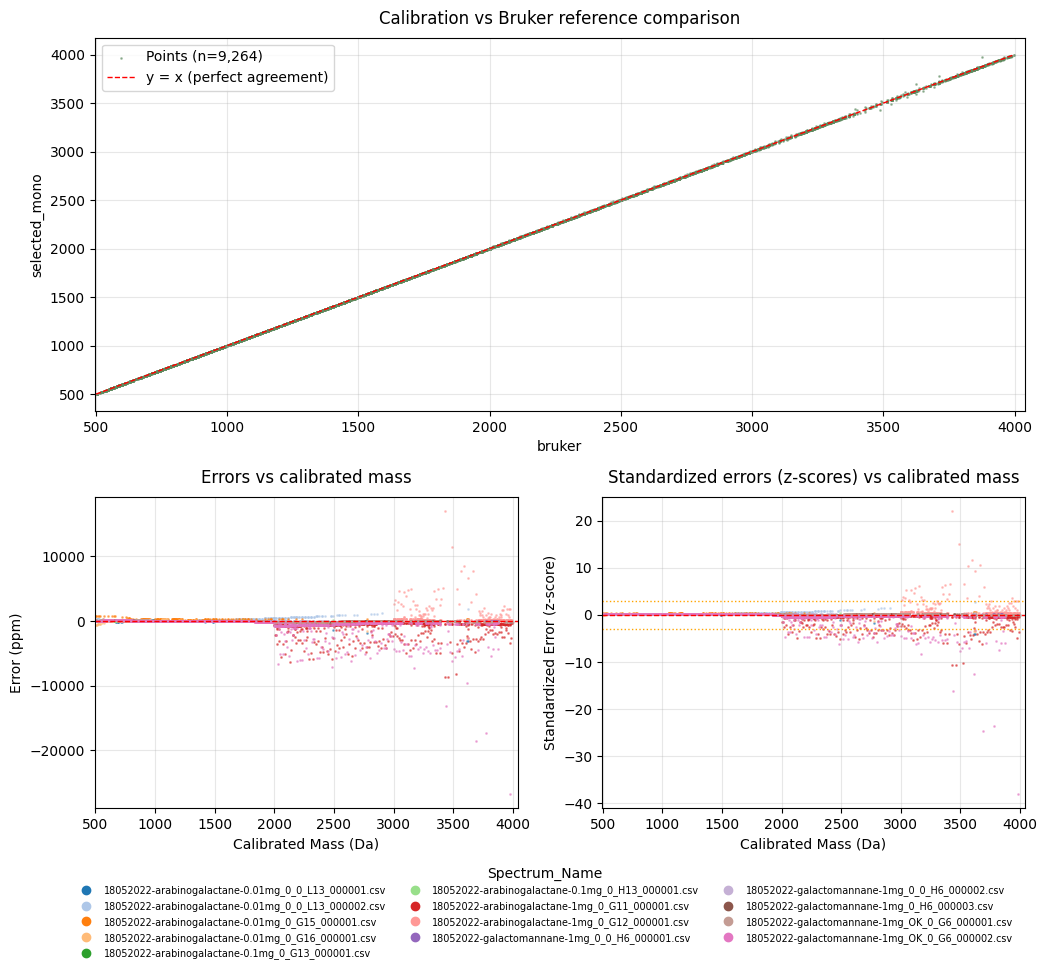

In [142]:
rmse_selected, mae_selected, r_2 = calculate_metrics(peaks_selected, ref_col="selected_mono", predict_col="bruker")
print(f"RMSE:  {rmse_selected} / MAE: {mae_selected} / R²: {r_2}")
plot_performance(
    peaks_selected,
    ref_col="bruker",
    predict_col="selected_mono",
    color="#5E8C61"  # Biochemistry-friendly color
)

Figure X. Evaluation of mass calibration accuracy relative to Bruker reference values. Calibrate versus Bruker reference masses (a), mass errors in ppm (b), and standardized errors (z-scores) (c) plotted against calibrated mass. Dashed and dotted lines indicate ideal agreement and ±3σ thresholds, respectively. Colors denote individual spectrum files.

#### Focus on reduce zone

RMSE:  0.12343267391833058 / MAE: 0.07843836335987285 / R²: 0.9999999055541002


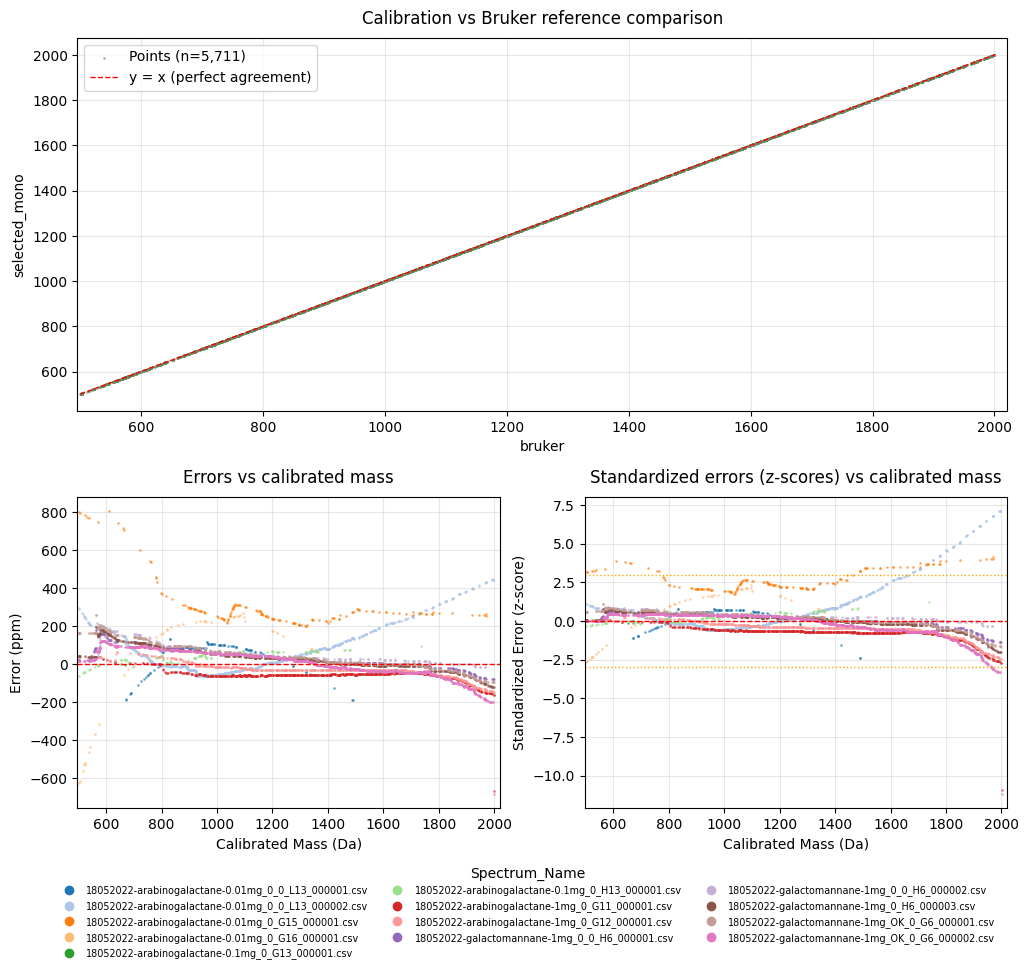

In [143]:
small_peaks_selected = peaks_selected.filter(pl.col("m/z")<2000)
rmse_selected, mae_selected, r_2 = calculate_metrics(small_peaks_selected, ref_col="selected_mono", predict_col="bruker")
print(f"RMSE:  {rmse_selected} / MAE: {mae_selected} / R²: {r_2}")
plot_performance(
    small_peaks_selected,
    ref_col="bruker",
    predict_col="selected_mono",
    color="#5E8C61",  # Biochemistry-friendly color
)

### With all Monomers

In [81]:
spectra = select_sepctrum(path_spectrum_all)
peaks_all = extract_and_concact_peaks(spectra, path_spectrum_all,path_peaks_all, "all_mono", workers)

18052022-arabinogalactane-0.01mg_0_0_L13_000001.csv
18052022-arabinogalactane-0.01mg_0_G15_000001.csv
18052022-arabinogalactane-0.01mg_0_G16_000001.csv
18052022-arabinogalactane-0.1mg_0_G13_000001.csv
18052022-arabinogalactane-0.1mg_0_H13_000001.csv
18052022-galactomannane-1mg_0_0_H6_000002.csv
[INFO] Starting analysis for 18052022-arabinogalactane-0.01mg_0_0_L13_000001.csv
[INFO] Extracting peaks of origninal spectrum
[INFO] Extracting peaks of calibrated spectrum
[INFO] Extracting peaks of bruker spectrum
[INFO] Join the spectrum
d:\Documents\codage\SugarMALDI\SugarMALDI\data\calibration\peaks\all\18052022-arabinogalactane-0.01mg_0_0_L13_000001.csv
[INFO] Starting analysis for 18052022-arabinogalactane-0.01mg_0_G15_000001.csv
[INFO] Extracting peaks of origninal spectrum
[INFO] Extracting peaks of calibrated spectrum
[INFO] Extracting peaks of bruker spectrum
[INFO] Join the spectrum
d:\Documents\codage\SugarMALDI\SugarMALDI\data\calibration\peaks\all\18052022-arabinogalactane-0.01mg

RMSE:  298.065985710522 / MAE: 100.57054328656476 / R²: 0.6589563809808439


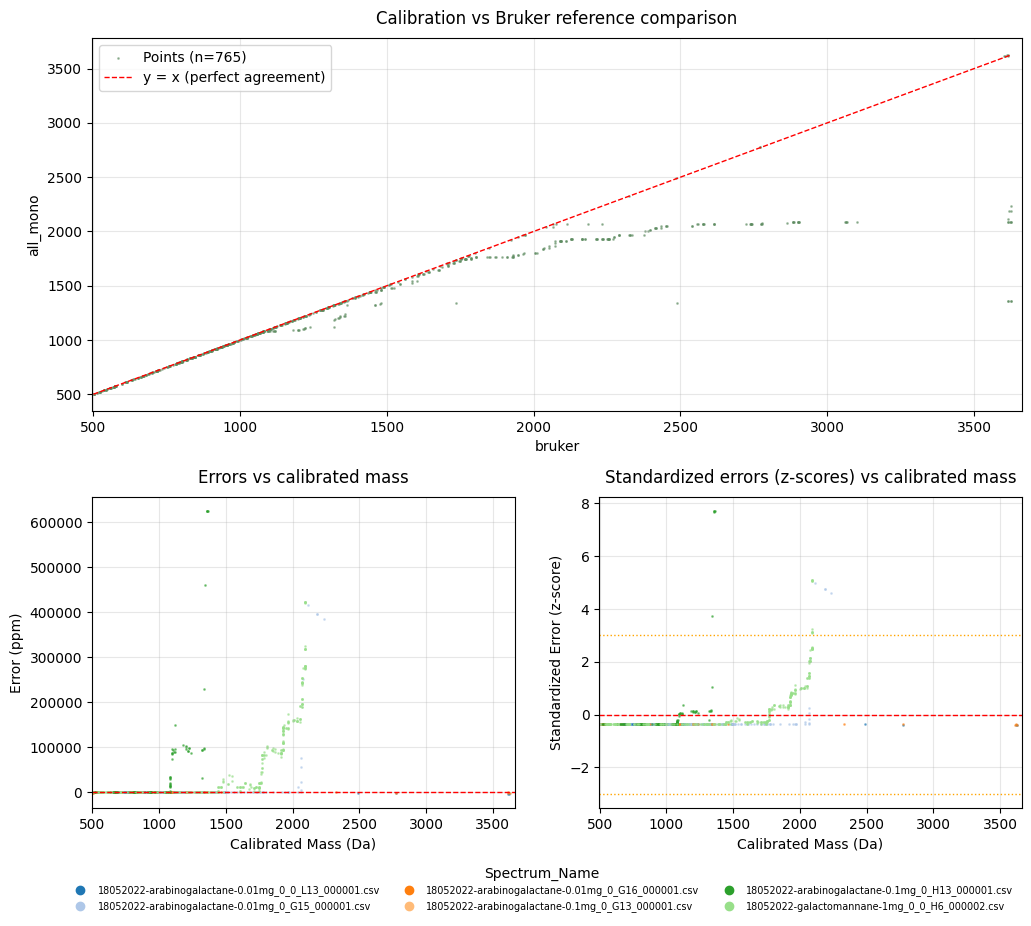

In [144]:
rmse_all, mae_all, r_2_all = calculate_metrics(peaks_all, ref_col="all_mono", predict_col="bruker")
print(f"RMSE:  {rmse_all} / MAE: {mae_all} / R²: {r_2_all}")
plot_performance(
    peaks_all,
    ref_col="bruker",
    predict_col="all_mono",
    color="#5E8C61"  # Biochemistry-friendly color
)

RMSE:  38.094150928162875 / MAE: 11.638320742784542 / R²: 0.9881882541741646


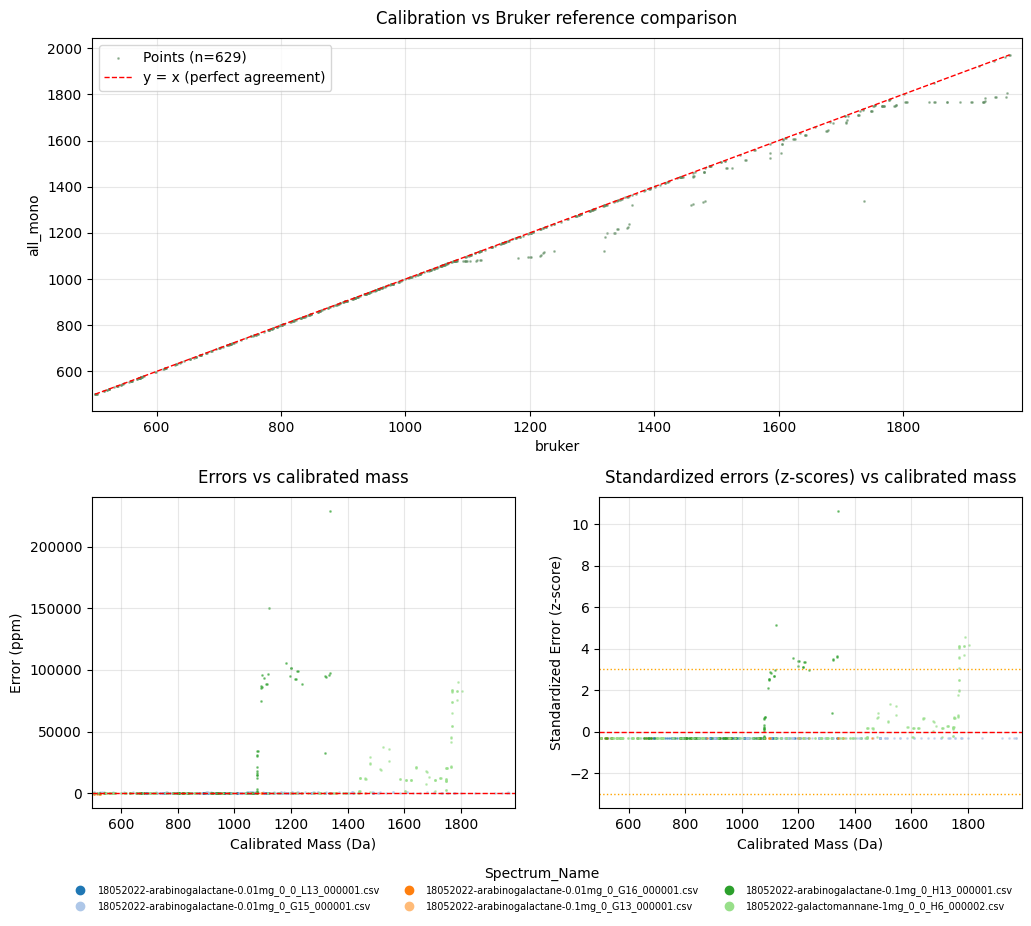

In [145]:
small_peaks_all = peaks_all.filter(pl.col("m/z")<2000)
rmse_selected, mae_selected, r_2 = calculate_metrics(small_peaks_all, ref_col="all_mono", predict_col="bruker")
print(f"RMSE:  {rmse_selected} / MAE: {mae_selected} / R²: {r_2}")
plot_performance(
    small_peaks_all,
    ref_col="bruker",
    predict_col="all_mono",
    color="#5E8C61",  # Biochemistry-friendly color
)

RMSE:  0.17914657282157478 / MAE: 0.11627058640908264 / R²: 0.9999985255733961


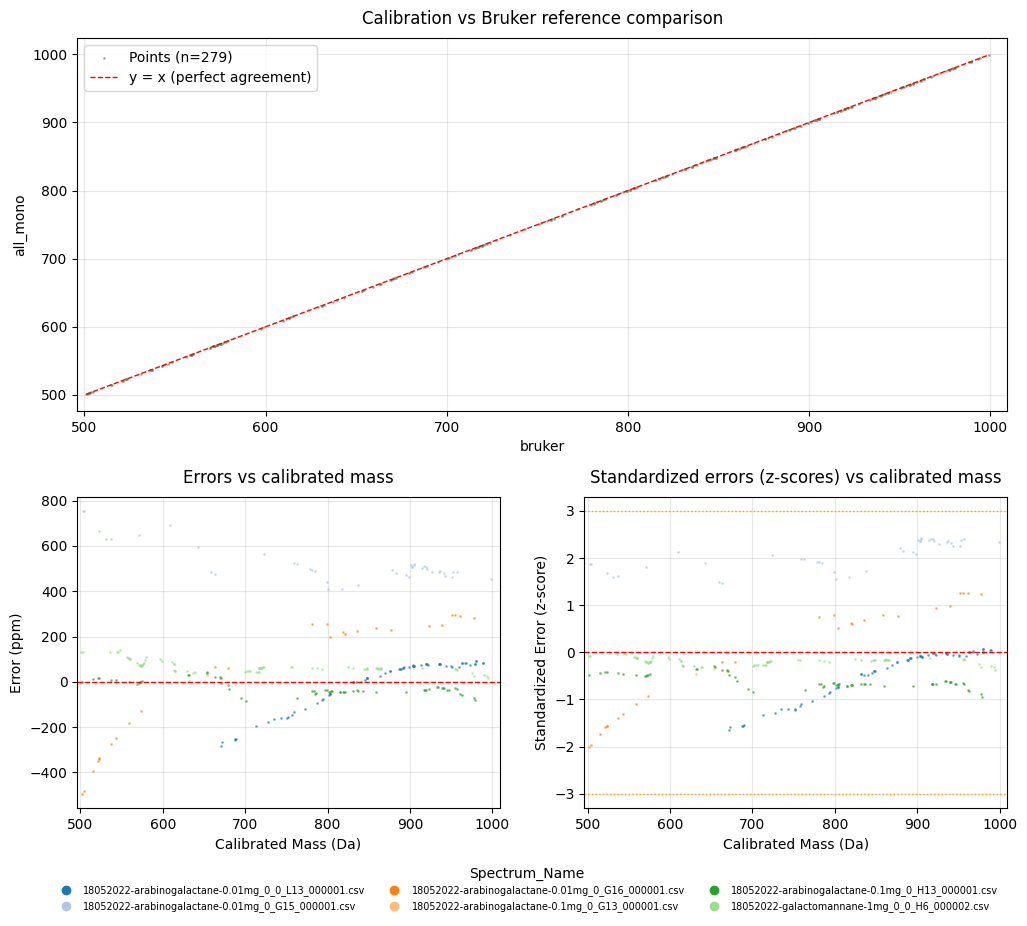

In [146]:
very_small_peaks_all = peaks_all.filter(pl.col("m/z")<1000)
rmse_selected, mae_selected, r_2 = calculate_metrics(very_small_peaks_all, ref_col="all_mono", predict_col="bruker")
print(f"RMSE:  {rmse_selected} / MAE: {mae_selected} / R²: {r_2}")
plot_performance(
    very_small_peaks_all,
    ref_col="bruker",
    predict_col="all_mono",
    color="#5E8C61",  # Biochemistry-friendly color
)